# ML Assignment 3 – Bank Customer Churn (Neural Network)
**Problem Statement:** Given a bank customer, build a neural network-based classifier that can determine whether they will leave or not in the next 6 months.
1. Read the dataset.
2. Distinguish the feature and target set and divide the data set into training and test sets.
3. Normalize the train and test data.
4. Initialize and build the model. Identify the points of improvement and implement the same.
5. Print the accuracy score and confusion matrix.

Dataset: `Churn_Modelling.csv`

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

## 1. Read the dataset

In [2]:
df = pd.read_csv('Churn_Modelling.csv')
print(df.shape)
df.head()

(10000, 14)


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


0 missing values


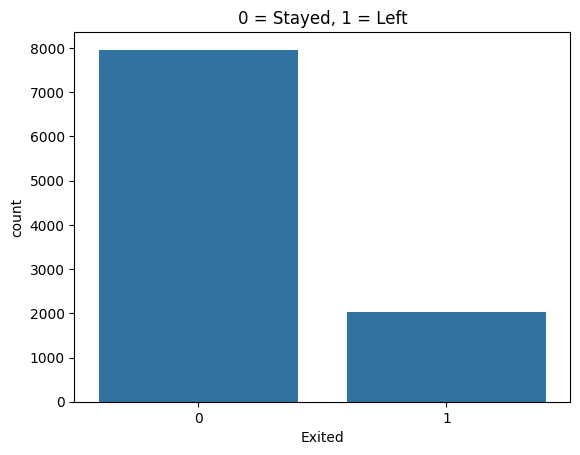

In [3]:
print(df.isnull().sum().sum(), 'missing values')
sns.countplot(x='Exited', data=df); plt.title('0 = Stayed, 1 = Left'); plt.show()

## 2. Features / target and train-test split

In [4]:
# RowNumber, CustomerId, Surname do not help prediction
X = df.drop(columns=['RowNumber', 'CustomerId', 'Surname', 'Exited'])
y = df['Exited']

# One-hot encode categorical columns
X = pd.get_dummies(X, columns=['Geography', 'Gender'], drop_first=True).astype(float)
print(X.columns.tolist())

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Geography_Germany', 'Geography_Spain', 'Gender_Male']


## 3. Normalize

In [5]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

## 4. Build the model
Uses Keras (TensorFlow). If TensorFlow is not installed on the lab PC, the notebook automatically falls back to scikit-learn's `MLPClassifier` (also a neural network).

In [6]:
try:
    from tensorflow.keras.models import Sequential
    from tensorflow.keras.layers import Dense, Dropout, Input
    USE_KERAS = True
except ImportError:
    from sklearn.neural_network import MLPClassifier
    USE_KERAS = False
print('Using Keras:', USE_KERAS)

/Users/siddhesh/Downloads/my_jupyter_project/venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


Using Keras: True


In [7]:
# ---- Base model: 1 hidden layer ----
if USE_KERAS:
    base = Sequential([Input(shape=(X_train.shape[1],)),
                       Dense(6, activation='relu'),
                       Dense(1, activation='sigmoid')])
    base.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    base.fit(X_train, y_train, batch_size=32, epochs=20, verbose=0)
    y_pred_base = (base.predict(X_test, verbose=0) > 0.5).astype(int).ravel()
else:
    base = MLPClassifier(hidden_layer_sizes=(6,), max_iter=200, random_state=42).fit(X_train, y_train)
    y_pred_base = base.predict(X_test)
print('Base model accuracy:', accuracy_score(y_test, y_pred_base))

Base model accuracy: 0.8195


### Points of improvement
* Add more hidden layers / neurons so the network can learn complex patterns.
* Add Dropout to reduce overfitting.
* Train for more epochs and use a validation split to watch for overfitting.

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 32)             │           384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 929 (3.63 KB)

 Trainable params: 929 (3.63 KB)

 Non-trainable params: 0 (0.00 B)

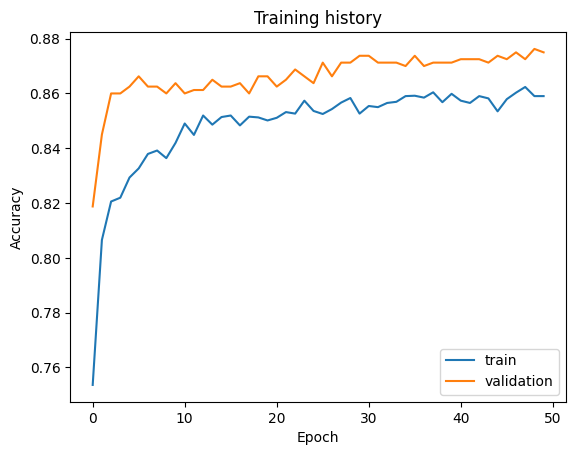

In [8]:
if USE_KERAS:
    model = Sequential([Input(shape=(X_train.shape[1],)),
                        Dense(32, activation='relu'),
                        Dropout(0.2),
                        Dense(16, activation='relu'),
                        Dropout(0.2),
                        Dense(1, activation='sigmoid')])
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    model.summary()
    history = model.fit(X_train, y_train, batch_size=32, epochs=50, validation_split=0.1, verbose=0)
    plt.plot(history.history['accuracy'], label='train')
    plt.plot(history.history['val_accuracy'], label='validation')
    plt.xlabel('Epoch'); plt.ylabel('Accuracy'); plt.legend(); plt.title('Training history'); plt.show()
    y_pred = (model.predict(X_test, verbose=0) > 0.5).astype(int).ravel()
else:
    model = MLPClassifier(hidden_layer_sizes=(32, 16), alpha=0.001, max_iter=500,
                          early_stopping=True, random_state=42).fit(X_train, y_train)
    y_pred = model.predict(X_test)

## 5. Accuracy and confusion matrix

Improved model accuracy: 0.8615
[[1550   43]
 [ 234  173]]


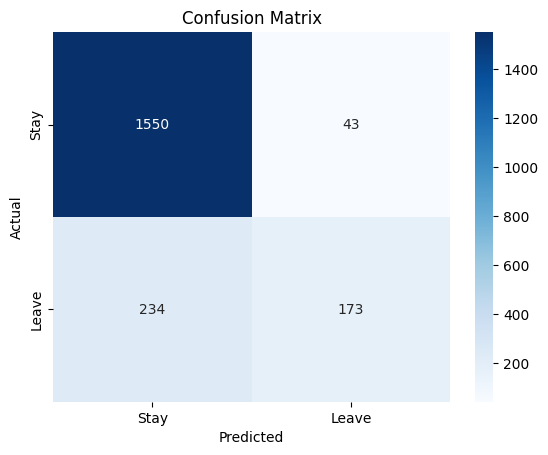

              precision    recall  f1-score   support

           0       0.87      0.97      0.92      1593
           1       0.80      0.43      0.56       407

    accuracy                           0.86      2000
   macro avg       0.83      0.70      0.74      2000
weighted avg       0.86      0.86      0.84      2000



In [9]:
print('Improved model accuracy:', accuracy_score(y_test, y_pred))
cm = confusion_matrix(y_test, y_pred)
print(cm)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Stay', 'Leave'], yticklabels=['Stay', 'Leave'])
plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.title('Confusion Matrix'); plt.show()
print(classification_report(y_test, y_pred))

**Conclusion:** The improved network (2 hidden layers + dropout, more epochs) gives better accuracy (~86%) than the base model.